# Global Power Plant Database Analysis
**Author:** Husnain Zahoor  
**Date:** Oct 25, 2026  
**Dataset:** Global Power Plant Database v1.2.0 (released 2019-06-12), World Resources Institute and data contributors.

**Version check:** I also checked the newer WRI v1.3.0 (June 2021). Saudi Arabia has 90 plants there but no reported generation for 2013 to 2019, so it would not remove the Saudi generation gap.

**Decision:** I kept v1.2.0 because it meets all Must-Have requirements and switching would not fix the limitation. The newer version is noted as a limitation in the write-up.

**Source URL:** https://datasets.wri.org/dataset/globalpowerplantdatabase

**Downloaded from:** Kaggle copy of the WRI release, https://www.kaggle.com/datasets/mathurinache/global-power-plant-database
**Licence:** CC BY 4.0. Copyright 2018-2019 World Resources Institute and Data Contributors

**Credit:** Global Energy Observatory, Google, KTH Royal Institute of Technology in Stockholm, Enipedia, World Resources Institute. 2019. Global Power Plant Database.

---

### Context & Pipeline Position
This notebook (1 of 5) handles data loading, cleaning, wrangling and consistency checks across global power plant dataset. It executes a documented data cleaning to produce the master cleaned dataset (df_power, saved as cleaned_power_plants.csv and df_final for modeling) for downstream analysis.

# Environment Setup

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
DATA_PATH = '/content/drive/MyDrive/Lumen Capstone Project/Dataset/'
OUTPUT_PATH = '/content/drive/MyDrive/Lumen Capstone Project/Output/'

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [4]:
# FORCE PANDAS TO SHOW ALL COLUMNS HORIZONTALLY (NO WRAPPING)
pd.set_option('display.max_columns', None)  # Show every column
pd.set_option('display.width', 1000)        # Give the text engine plenty of horizontal width

# Loading the data set

**Exercise#1: Clean your dataset.** Run the cleaning checklist from Section 2 against your own capstone dataset. Fix or document every missing-value, duplicate, and outlier case; correct any data-type issues. Submit your cleaned dataset (CSV) plus a short cleaning log: what you found, what you did about it, and why.

In [5]:
# Loading the raw file (default pandas encoding reads accented names correctly)
df_power = pd.read_csv(DATA_PATH + 'global_power_plant_database.csv')
print(f"Loaded successfully: {df_power.shape[0]} rows, {df_power.shape[1]} columns")

Loaded successfully: 29910 rows, 24 columns


In [6]:
df_power.dtypes

,0
country,object
country_long,object
name,object
gppd_idnr,object
capacity_mw,float64
latitude,float64
longitude,float64
primary_fuel,object
other_fuel1,object
other_fuel2,object


# Converting Data Types

In [7]:
# Check actual Python types within each column
for col in df_power.columns:
    unique_types = df_power[col].map(type).unique()
    print(f"{col}: {unique_types}")

country: [<class 'str'>]
country_long: [<class 'str'>]
name: [<class 'str'>]
gppd_idnr: [<class 'str'>]
capacity_mw: [<class 'float'>]
latitude: [<class 'float'>]
longitude: [<class 'float'>]
primary_fuel: [<class 'str'>]
other_fuel1: [<class 'float'> <class 'str'>]
other_fuel2: [<class 'float'> <class 'str'>]
other_fuel3: [<class 'float'> <class 'str'>]
commissioning_year: [<class 'float'>]
owner: [<class 'float'> <class 'str'>]
source: [<class 'str'> <class 'float'>]
url: [<class 'str'> <class 'float'>]
geolocation_source: [<class 'str'> <class 'float'>]
wepp_id: [<class 'str'> <class 'float'>]
year_of_capacity_data: [<class 'float'>]
generation_gwh_2013: [<class 'float'>]
generation_gwh_2014: [<class 'float'>]
generation_gwh_2015: [<class 'float'>]
generation_gwh_2016: [<class 'float'>]
generation_gwh_2017: [<class 'float'>]
estimated_generation_gwh: [<class 'float'>]


In [8]:
# checking the decimal values in commissioning_year column:
decimal = df_power[df_power['commissioning_year'].notna() & (df_power['commissioning_year'] % 1 != 0)]
print('Total decimal values:', len(decimal))
print(decimal['commissioning_year'].head(10).tolist())

Total decimal values: 2002
[1997.4, 1993.5, 1999.5, 1997.7, 1999.4, 1993.3, 2008.7, 2008.7, 1983.9, 2002.5]


In [9]:
# Correcting the decimal values to consistent int data type in commissioning_year and year_of_capacity_data columns.

df_power['commissioning_year_raw'] = df_power['commissioning_year']
df_power['commissioning_year'] = np.floor(df_power['commissioning_year'] + 0.5).astype('Int64')
df_power['year_of_capacity_data'] = df_power['year_of_capacity_data'].astype('Int64')

# Check the commissioning_year column range:
print('Year_Range:', df_power['commissioning_year'].min(), 'to', df_power['commissioning_year'].max())


Year_Range: 1896 to 2018


In [10]:
# Shows the first 10 plants whose commissioning year had a decimal, with the original value next to the rounded one.

changed = df_power[df_power['commissioning_year_raw'].notna() & (df_power['commissioning_year_raw'] % 1 != 0)]
print(changed[['name', 'commissioning_year_raw', 'commissioning_year']].head(10))

                                         name  commissioning_year_raw  commissioning_year
63     AGUA DEL CAJON (AUTOGENERADOR DEL MEM)                  1997.4                1997
64         AGUA DEL CAJON (GENERADOR DEL MEM)                  1993.5                1994
91                 CENTRAL LOMA DE LA LATA SA                  1999.5                2000
93                          CENTRAL T.GENELBA                  1997.7                1998
96   CENTRAL TERMICA DE CICLO COMBINADO SALTA                  1999.4                1999
97                  CENTRAL TERMICA GÜEMES SA                  1993.3                1993
102    CENTRAL TERMOELECTRICA MANUEL BELGRANO                  2008.7                2009
103            CENTRAL TERMOELECTRICA TIMBUES                  2008.7                2009
112                                 COSTANERA                  1983.9                1984
169                       CT PLUSPETROL NORTE                  2002.5                2003


In [11]:
# Checking the both columns data types:
df_power[['commissioning_year','year_of_capacity_data']].dtypes

,0
commissioning_year,Int64
year_of_capacity_data,Int64


**Data types:** `commissioning_year` was stored with decimals (e.g. 1997.4) for 2002 plants, likely an average across the units of multi-unit plants. I kept the original in `commissioning_year_raw`, rounded half-up to a whole year and converted it to Int64. `year_of_capacity_data` had no decimals and was converted directly. Capacity, generation and coordinates stay as decimals.

# Handling Missing Values

In [12]:
# Checking the missing values, excluding the backup column so it isn't double-counted:
missing = df_power.drop(columns='commissioning_year_raw').isnull().sum().to_frame('missing_count')
missing['missing_pct'] = (missing['missing_count'] / len(df_power) * 100).round(2)
print(missing.sort_values('missing_pct', ascending=False))
print()

df_check = df_power.drop(columns='commissioning_year_raw')
print(f"Total missing values: {df_check.isnull().sum().sum()}")
print(f"Actual dataset rows: {len(df_check)}")
print(f"Null rate: {df_check.isnull().sum().sum() / (len(df_check) * len(df_check.columns)):.1%}")

                          missing_count  missing_pct
other_fuel3                       29806        99.65
other_fuel2                       29607        98.99
other_fuel1                       27947        93.44
generation_gwh_2013               22914        76.61
generation_gwh_2014               22470        75.13
generation_gwh_2015               21766        72.77
generation_gwh_2016               20939        70.01
generation_gwh_2017               20697        69.20
year_of_capacity_data             16167        54.05
commissioning_year                13607        45.49
wepp_id                           13529        45.23
owner                             10379        34.70
estimated_generation_gwh           8119        27.14
geolocation_source                  419         1.40
url                                  18         0.06
source                               15         0.05
primary_fuel                          0         0.00
longitude                             0       

## What I found and decided

**What was checked:** the number and percentage of empty cells in each of the 24 original columns (29,910 plants). The backup column `commissioning_year_raw` is excluded so it isn't counted twice.

**Overall:** 258,399 of 717,840 cells are empty (36.0%). Most of this comes from a few columns that the analysis does not use.

| Group | Columns | Missing | What it means | Decision |
|---|---|---|---|---|
| Complete | `country`, `country_long`, `name`, `gppd_idnr`, `capacity_mw`, `latitude`, `longitude`, `primary_fuel` | 0% | Every plant has these | Nothing needed |
| Almost empty | `other_fuel1`, `other_fuel2`, `other_fuel3` | 93.44% to 99.65% | Most plants have no second or third fuel, so a blank means "none" | Kept as is, not used in the analysis |
| Generation | `generation_gwh_2013` to `generation_gwh_2017` | 69.20% to 76.61% | Most countries do not report plant-level output | Not filled. Only plants that report output are used (9,213 for 2017) |
| Commissioning year | `commissioning_year` | 45.49% | Often missing for older plants or countries with no digital records | Not filled. Rows without it are left out of clustering and regression |
| Not used | `year_of_capacity_data`, `wepp_id`, `owner`, `estimated_generation_gwh`, `geolocation_source`, `url`, `source` | 0.05% to 54.05% | Reference columns, not used in the analysis | Left as is |

**Why missing values were not filled:** the data is self-reported by national regulators, so blanks are not random. Older plants and countries with weaker reporting are missing more often. Filling them with averages would invent numbers, and for `generation_gwh_2017` (the regression target) it would make the model's R² meaningless.

**Impact on the analysis:** the regression and clustering use only plants that have both `generation_gwh_2017` and `commissioning_year`, which is 8,778 plants (see Final N) rows.

# Checking for Outliers

In [13]:
Q1, Q3 = df_power["capacity_mw"].quantile([0.25, 0.75])
IQR = Q3 - Q1
outliers = df_power[(df_power["capacity_mw"] < Q1 - 1.5 * IQR) | (df_power["capacity_mw"] > Q3 + 1.5 * IQR)]
print("Lower cutoff:", round(Q1 - 1.5 * IQR, 2), "MW")
print("Upper cutoff:", round(Q3 + 1.5 * IQR, 2), "MW")
print(f"Flagged Plants: {len(outliers)} ({len(outliers) / len(df_power):.1%} of all rows)")

Lower cutoff: -138.06 MW
Upper cutoff: 242.84 MW
Flagged Plants: 4785 (16.0% of all rows)


**IQR outlier check** (not used for decisions). The IQR rule flagged 4,785 plants (16%) above 242.84 MW, with a negative lower cutoff of -138 MW, so the rule flags every large plant. I checked the 10 largest plants against outside sources (e.g. Three Gorges) and they are real, so I kept all flagged plants. The rest are above 242 MW but physically plausible. **(see the top 10 below).**

In [14]:
# This shows the spread of capacity_mw across all 29,910 plants, plus how many are zero or negative (which would be errors).
# And counts the plants above 10,000 MW and shows the 10 largest.

print(df_power['capacity_mw'].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).round(2))
print("\nZero or negative:", (df_power['capacity_mw'] <= 0).sum())
print("Below 1 MW:", (df_power['capacity_mw'] < 1).sum())
print("Above 10,000 MW:", (df_power['capacity_mw'] > 10000).sum())
df_power.nlargest(10, 'capacity_mw')[['name', 'country_long', 'primary_fuel', 'capacity_mw']]

count    29910.00
mean       186.29
std        525.70
min          1.00
1%           1.00
5%           1.26
25%          4.77
50%         18.90
75%        100.00
95%       1050.00
99%       2469.19
max      22500.00
Name: capacity_mw, dtype: float64

Zero or negative: 0
Below 1 MW: 0
Above 10,000 MW: 3


,name,country_long,primary_fuel,capacity_mw
7298,Three Gorges Dam,China,Hydro,22500.0
4888,Baihetan Dam,China,Hydro,13050.0
7484,Xiluodu,China,Hydro,12600.0
16327,Surgutskaya GRES-2,Russia,Gas,8865.0
29659,Simon Bolivar (Guri),Venezuela,Hydro,8851.0
3147,Tucuruí,Brazil,Hydro,8535.0
13701,Kashiwazaki Kariwa,Japan,Nuclear,8212.0
2082,Itaipu (Parte Brasileira),Brazil,Hydro,7000.0
5302,East Hope Metals Wucaiwan power station,China,Coal,7000.0
15108,Itaipu Binacional Dam (Paraguay part),Paraguay,Hydro,7000.0


The typical plant in my data is about 19 MW, but the average is 186 MW because a few giants plants pull the mean up. I used the standard IQR rule to find unusually large plants and it flagged 16%. I checked them, and they’re real large plants like Three Gorges, so I kept them. There are no zero or negative values, and the smallest plant is exactly 1 MW.

# Statistical Summary using df.describe()

In [15]:
cols = ['capacity_mw','commissioning_year', 'generation_gwh_2013', 'generation_gwh_2014',
        'generation_gwh_2015', 'generation_gwh_2016', 'generation_gwh_2017',
        'latitude', 'longitude']
df_power[cols].describe().round(2)

,capacity_mw,commissioning_year,generation_gwh_2013,generation_gwh_2014,generation_gwh_2015,generation_gwh_2016,generation_gwh_2017,latitude,longitude
count,29910.00,16303.0,6996.00,7440.00,8144.00,8971.00,9213.00,29910.00,29910.00
mean,186.29,1995.49,689.63,664.84,664.27,583.62,579.52,32.50,-12.46
std,525.70,23.52,2330.87,2258.35,2304.23,2097.60,2063.07,23.65,76.98
min,1.00,1896.0,-947.60,-989.62,-864.43,-768.62,-934.94,-77.85,-179.98
25%,4.77,1986.0,2.17,2.16,2.35,2.38,3.20,28.86,-79.21
50%,18.90,2005.0,27.03,23.00,22.09,17.86,20.46,40.07,-3.75
75%,100.00,2012.0,250.60,224.96,238.44,187.08,192.57,47.13,24.93
max,22500.00,2018.0,50834.00,32320.92,59546.86,32377.48,35116.00,71.29,179.39


**Reading the summary:** Capacity and generation are heavily skewed (median far below mean), so I use the median for the typical plant and a log transform before clustering. Commissioning year runs 1896 to 2018. The generation columns have far fewer values (6,996 to 9,213) than the 29,910 plants.

In [16]:
# This counts the negative 2017 rows, shows which fuel types they belong to,
# and counts plants that reporting more electricity than they could physically produce at full capacity all year.

neg = df_power[df_power['generation_gwh_2017'] < 0]
print("Negative 2017 rows:", len(neg))
print(neg['primary_fuel'].value_counts())
print(f"\nPlants producing energy above capacity: {(df_power['generation_gwh_2017'] > df_power['capacity_mw'] * 8.76).sum()}")

Negative 2017 rows: 180
primary_fuel
Oil             76
Gas             41
Storage         30
Hydro           30
Solar            1
Waste            1
Cogeneration     1
Name: count, dtype: int64

Plants producing energy above capacity: 14


**14 plants** report more electricity than they could produce running at full capacity all year (capacity × 8,760 hours). That is **physically impossible**, so these are **errors**.


180 plants have negative output (about 2% of the 9,213). Oil, gas, storage and hydro make up almost all of them. A negative can be real, for example a plant that used more power than it produced that year, but that’s a guess until we look at the rows.

In [17]:
# This lists the 14 impossible plants with their capacity, reported 2017 output and how many times over the maximum they are,
# so we can see whether they’re typos or something else.

imp_plants = df_power[df_power['generation_gwh_2017'] > df_power['capacity_mw'] * 8.76].copy()
imp_plants['times_over_max'] = (imp_plants['generation_gwh_2017'] / (imp_plants['capacity_mw'] * 8.76)).round(2)
imp_plants[['name', 'country_long', 'primary_fuel', 'capacity_mw', 'generation_gwh_2017', 'times_over_max']].sort_values('times_over_max', ascending=False)

,name,country_long,primary_fuel,capacity_mw,generation_gwh_2017,times_over_max
724,Wyndham,Australia,Waste,1.0,14.794722,1.69
26207,Nooksack Hydro,United States of America,Hydro,1.5,21.012000,1.60
27579,San Juan,United States of America,Coal,924.0,10859.285930,1.34
534,Moranbah North,Australia,Gas,45.7,490.229444,1.22
610,Rockingham,Australia,Waste,2.1,21.183056,1.15
26527,Oyster Creek,United States of America,Nuclear,550.0,5430.191000,1.13
24081,Hailesboro 4 Plant,United States of America,Hydro,1.4,13.203000,1.08
24182,Hauser,United States of America,Hydro,14.2,130.317000,1.05
21760,Brent Run Generating Station,United States of America,Waste,5.4,48.998000,1.04
28322,Superior Falls,United States of America,Hydro,1.4,12.600000,1.03


In [18]:
# This shows, for the 14 plants, the capacity year plus how far over the maximum they are in 2015, 2016 and 2017.
# If they’re over in every year, the capacity figure is probably understated. If only in 2017, the generation figure is probably the problem.

imp_plants = df_power[df_power['generation_gwh_2017'] > df_power['capacity_mw'] * 8.76].copy()
for y in [2015, 2016, 2017]:
    imp_plants[f'over_{y}'] = (imp_plants[f'generation_gwh_{y}'] / (imp_plants['capacity_mw'] * 8.76)).round(2)
imp_plants[['name', 'capacity_mw', 'year_of_capacity_data', 'over_2015', 'over_2016', 'over_2017']]

,name,capacity_mw,year_of_capacity_data,over_2015,over_2016,over_2017
534,Moranbah North,45.7,<NA>,1.10,1.16,1.22
609,Rochedale,4.0,<NA>,0.97,0.98,1.02
610,Rockingham,2.1,<NA>,1.17,1.15,1.15
724,Wyndham,1.0,<NA>,1.76,1.75,1.69
21760,Brent Run Generating Station,5.4,2017,0.84,0.93,1.04
24081,Hailesboro 4 Plant,1.4,2017,0.82,0.81,1.08
24182,Hauser,14.2,2017,0.98,0.97,1.05
25641,Menominee Mill Marinette,1.8,2017,0.97,0.81,1.03
26207,Nooksack Hydro,1.5,2017,1.69,1.85,1.60
26322,OREG 3 Inc,5.0,2017,1.00,1.07,1.01


### Plants reporting more output than physically possible (14 plants)

Each plant has a ceiling: the most electricity it could produce in a year if it ran at full capacity all year (capacity in MW × 8.76 = GWh). A value above 1.00 in the table means the plant reported more than its ceiling, which is impossible, so the reported number is wrong somewhere.

- **Over the ceiling in all three years (5 plants):** Wyndham, Nooksack Hydro, Rockingham, Moranbah North and San Juan. Wyndham and Nooksack are 1.6 to 1.85 times over every year. A steady overshoot like this suggests the plant's capacity figure is too low or out of date. This is the likely explanation, not a confirmed one.
- **Slightly over in 2017 (8 plants):** Brent Run, Hailesboro 4, Hauser, Menominee Mill, Rochedale, OREG 3, St Francisville and Superior Falls are only 1% to 8% over in 2017. This looks like a slightly high 2017 figure or rounding, not a wrong capacity.
- **Mixed (1 plant):** Oyster Creek is over in 2015 and 2017 but under in 2016.

**Decision:** all 14 plants are kept in the dataset and flagged (`flag_over_max`). They are excluded from clustering and regression only, because their 2017 output cannot be trusted as a correct answer for the model. This is 14 of 9,213 plants with 2017 data (0.15%), so excluding them has almost no effect.

In [19]:
# Adds a True/False column called flag_over_max to the main table (no rows deleted) and counts the flagged plants.

df_power['flag_over_max'] = df_power['generation_gwh_2017'] > df_power['capacity_mw'] * 8.76
print("Flagged:", df_power['flag_over_max'].sum())

Flagged: 14


In [20]:
# This shows the 10 most negative 2017 plants with their capacity, fuel, and their 2015 and 2016 output beside them.

neg = df_power[df_power['generation_gwh_2017'] < 0]
neg.nsmallest(10, 'generation_gwh_2017')[['name', 'country_long', 'primary_fuel', 'capacity_mw', 'generation_gwh_2015', 'generation_gwh_2016', 'generation_gwh_2017']]

,name,country_long,primary_fuel,capacity_mw,generation_gwh_2015,generation_gwh_2016,generation_gwh_2017
21397,Bath County,United States of America,Hydro,2862.0,-864.428,-768.620,-934.944
27089,Raccoon Mountain,United States of America,Hydro,1713.6,-530.702,-703.946,-686.154
25343,Ludington,United States of America,Hydro,1978.8,-480.821,-751.650,-674.759
21333,Bad Creek,United States of America,Hydro,1296.0,-531.676,-572.652,-623.387
27339,Rocky Mountain Hydroelectric Plant,United States of America,Hydro,847.8,-489.613,-489.099,-534.990
25961,Muddy Run,United States of America,Hydro,1072.0,-319.003,-360.845,-413.465
26276,Northfield Mountain,United States of America,Hydro,940.0,-313.833,-349.056,-339.776
24232,Helms Pumped Storage,United States of America,Hydro,1053.0,-250.413,-498.562,-290.220
25172,Lewiston Niagara,United States of America,Hydro,240.0,-245.347,-284.770,-252.637
24726,Jocassee,United States of America,Hydro,774.0,-248.787,-206.937,-249.972


In [21]:
# This adds the flag for pumped-storage-type negatives, keeping every row.

df_power['flag_negative_gen_2017'] = df_power['generation_gwh_2017'] < 0
print("Flagged:", df_power['flag_negative_gen_2017'].sum())

Flagged: 180


**Negative generation:** The 10 most negative plants are US pumped-storage hydro (e.g. Bath County, Ludington), negative in 2015, 2016 and 2017. **This fits net output:** they use more power pumping water uphill than they send out. The 76 oil and 41 gas negatives have not been investigated and are noted as a limitation. All 180 are flagged, kept, and excluded from clustering and regression only.

# Data Structure Check (df.info())

In [22]:
# Excluding the backup commissioning_year_raw column.
df_power.drop(columns=['commissioning_year_raw']).info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29910 entries, 0 to 29909
Data columns (total 26 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   country                   29910 non-null  object 
 1   country_long              29910 non-null  object 
 2   name                      29910 non-null  object 
 3   gppd_idnr                 29910 non-null  object 
 4   capacity_mw               29910 non-null  float64
 5   latitude                  29910 non-null  float64
 6   longitude                 29910 non-null  float64
 7   primary_fuel              29910 non-null  object 
 8   other_fuel1               1963 non-null   object 
 9   other_fuel2               303 non-null    object 
 10  other_fuel3               104 non-null    object 
 11  commissioning_year        16303 non-null  Int64  
 12  owner                     19531 non-null  object 
 13  source                    29895 non-null  object 
 14  url   

# Checking Duplicates

In [23]:
num_duplicates = df_power.duplicated().sum()
print(f"Eact Duplicate rows: {num_duplicates}")

Eact Duplicate rows: 0


In [24]:
# This checks for duplicate plant IDs, and for duplicate plants by name, country and exact coordinates.

print("Duplicate plant IDs:", df_power['gppd_idnr'].duplicated().sum())
print("Same name + country + coordinates (different plants can share a site):", df_power.duplicated(subset=['name', 'country', 'latitude', 'longitude']).sum())

Duplicate plant IDs: 0
Same name + country + coordinates (different plants can share a site): 97


In [25]:
# This shows the first 20 rows from the 97 pairs side by side, sorted by name, with ID, fuel, capacity and 2017 output.

dupe_mask = df_power.duplicated(subset=['name', 'country', 'latitude', 'longitude'], keep=False)
df_power[dupe_mask].sort_values(['name', 'country'])[['name', 'country', 'gppd_idnr', 'primary_fuel', 'capacity_mw', 'generation_gwh_2017']].head(20)

,name,country,gppd_idnr,primary_fuel,capacity_mw,generation_gwh_2017
16841,AGREDA,ESP,WRI1006162,Wind,18.00000,NaN
16842,AGREDA,ESP,WRI1006163,Waste,16.33400,NaN
8834,Aiguillon,FRA,WRI1025631,Hydro,1.17700,NaN
8835,Aiguillon,FRA,WRI1025153,Solar,2.57727,NaN
8839,Aix-en-Provence,FRA,WRI1024988,Biomass,4.24500,NaN
8840,Aix-en-Provence,FRA,WRI1024662,Solar,8.36119,NaN
8896,Arpajon-sur-Cère,FRA,WRI1024971,Biomass,4.41000,NaN
8897,Arpajon-sur-Cère,FRA,WRI1024413,Solar,11.27645,NaN
8934,Avignonet-Lauragais,FRA,WRI1024184,Wind,12.60000,NaN
8935,Avignonet-Lauragais,FRA,WRI1024930,Solar,4.77224,NaN


The 97 rows sharing name, country and coordinates are not duplicates. They have different plant IDs, fuel types and capacities (e.g. a wind farm and a solar plant listed at the same site, or the Bandar Abbas gas and oil units). WRI lists them as separate facilities. No rows were removed.

In [26]:
# This counts rows that match on name, country, coordinates, fuel and capacity, which is what a real duplicate would look like.

strict = df_power.duplicated(subset=['name', 'country', 'latitude', 'longitude', 'primary_fuel', 'capacity_mw']).sum()
print("Strict duplicates:", strict)

Strict duplicates: 0


# Final Dataset for Modelling (Final N)

In [27]:
# Final N means how many plants are actually left in the analysis after everything that can’t be used is removed.
# It matters because dataset has 29,910 plants, but the clustering and regression can’t use all of them. A plant has to pass these filters:

# This counts how many plants pass all three filters.

df_final = df_power[
    df_power['generation_gwh_2017'].notna()        # Has a generation_gwh_2017 value (9,213 plants do)
    & df_power['commissioning_year'].notna()       # Also has a commissioning_year value
    & ~df_power['flag_over_max']
    & ~df_power['flag_negative_gen_2017']          # Is not flagged as over capacity (14 plants) or negative (180 plants)
].copy()
print("Final N:", len(df_final))

Final N: 8778


**Rows available for modelling:** Clustering and regression use only plants with both a 2017 generation figure and a commissioning year, excluding the 14 plants above their physical maximum and the 180 with negative output. That leaves 8,778 of 29,910 plants (29.3%). Of these, 8,345 are in the USA (95%), 431 in India (5%), and 2 in Morocco and South Africa. Saudi Arabia has none: its 86 plants have capacity and commissioning year, but no generation figures. The model results therefore describe US plants and should not be read as global or as Saudi. Saudi analysis will use capacity, which is filled for all 86 Saudi plants.

**Australia** (243 plants) drops out because it has no commissioning year.

In [28]:
# This shows the top 10 countries and the fuel breakdown inside the 8,778 plants, plus how many are Saudi.

print(df_final['country'].value_counts().head(10))
print('\n',df_final['primary_fuel'].value_counts())
print("\nSaudi plants in final N:", (df_final['country'] == 'SAU').sum())

country
USA    8345
IND     431
MAR       1
ZAF       1
Name: count, dtype: int64

 primary_fuel
Solar           2262
Gas             1717
Hydro           1571
Wind            1040
Oil              745
Waste            552
Coal             517
Biomass          155
Nuclear           68
Geothermal        64
Cogeneration      31
Storage           28
Other             16
Petcoke           12
Name: count, dtype: int64

Saudi plants in final N: 0


In [29]:
# This shows which countries have any 2017 generation data, whether Saudi has WRI’s estimated generation figure, and Saudi capacity by fuel type.

print(df_power.groupby('country')['generation_gwh_2017'].count().sort_values(ascending=False).head(10))
sau = df_power[df_power['country'] == 'SAU']
print("\nSaudi plants:", len(sau), "| estimated_generation_gwh filled:", sau['estimated_generation_gwh'].notna().sum())
print(sau.groupby('primary_fuel')['capacity_mw'].agg(['count', 'sum']).round(0).sort_values('sum', ascending=False))

country
USA    8535
IND     431
AUS     243
MAR       2
POL       1
ZAF       1
ARM       0
ARG       0
ARE       0
AZE       0
Name: generation_gwh_2017, dtype: int64

Saudi plants: 86 | estimated_generation_gwh filled: 86
              count      sum
primary_fuel                
Oil              53  49702.0
Gas              31  34502.0
Solar             2     14.0


**Generation coverage:** Only six countries report 2017 generation (USA 8,535, India 431, Australia 243, Morocco 2, Poland 1, South Africa 1). Saudi Arabia has none, so no Saudi plant is in the modelling data. Its 86 plants have capacity, fuel and commissioning year. WRI's `estimated_generation_gwh` is filled for all 86 but is a modelled estimate, not measured output, so it is not used.

In [30]:
df_power.to_csv(OUTPUT_PATH + 'cleaned_power_plants.csv', index=False, encoding='utf-8-sig')
print("Saved: cleaned_power_plants.csv:", df_power.shape[0], "rows,", df_power.shape[1], "columns")

Saved: cleaned_power_plants.csv: 29910 rows, 27 columns


In [31]:
df_power.to_pickle(OUTPUT_PATH + 'cleaned_power_plants.pkl')
print("Saved: cleaned_power_plants.pkl:", df_power.shape[0], "rows,", df_power.shape[1], "columns")

Saved: cleaned_power_plants.pkl: 29910 rows, 27 columns


# Consistency Log

In [32]:
consistency_log = pd.DataFrame([
    {"Check": "Text encoding",                     "Finding": "name values looked garbled (e.g. BÃ©cancour) when the CSV was opened in Excel, but pandas reads them correctly (e.g. Bécancour). The garbling was an Excel display issue, not a data issue", "Action Taken": "No change needed. Default pandas loading is correct; Used utf-8-sig when saving, so Excel shows accents correctly."},
    {"Check": "Text encoding",                     "Finding": "4 Denmark plant names are broken inside the file itself (e.g. AvedÃ¸re instead of Avedøre). 13 Brazil rows containing Ã are correct (Ã is a real Portuguese letter)", "Action Taken": "Left as-is, documented as a known unresolved issue (4 rows, labelling only)"},
    {"Check": "Data types",                        "Finding": "commissioning_year was float, with 2002 non-whole values (e.g. 1997.4), likely averaged across units of multi-unit plants. 13,607 blanks.", "Action Taken": "Kept original as commissioning_year_raw, rounded to the nearest year (halves rounded up), converted to Int64. Verified: Sample of changed rows checked."},
    {"Check": "Data types",                        "Finding": "year_of_capacity_data was float with no decimals", "Action Taken": "Converted to Int64, no rounding needed"},
    {"Check": "Missing values",                    "Finding": "other_fuel1/2/3 were 93.4%-99.7% missing", "Action Taken": "Kept as is, not used in analysis, documented missing %"},
    {"Check": "Missing values",                    "Finding": "generation_gwh_2017 (regression target) was 69.2% missing", "Action Taken": "Not filled - excluded from clustering/regression, only ~9,213 rows used"},
    {"Check": "Missing values",                    "Finding": "commissioning_year was 45.5% missing overall, but 0% missing for Saudi rows(Excel / outside research)", "Action Taken": "Not filled - excluded from clustering/regression where missing"},
    {"Check": "capacity_mw validity",              "Finding": "Minimum is 1.0 MW, no zero or negative values. Only 3 plants exceed 10,000 MW (Three Gorges 22,500 MW, Baihetan 13,050 MW, Xiluodu 12,600 MW). Verified in raw data and against outside research: Three Gorges (China) is the largest power plant in the world at ~22,500 MW, so no value exceeds what is physically possible", "Action Taken": "No rows removed or changed; all values accepted as genuine"},
    {"Check": "capacity_mw outliers (IQR)",        "Finding": "IQR rule (1.5 x IQR) flagged 4,785 plants (16.0%) above 242.84 MW; lower cutoff (-138.06 MW) is below zero so nothing flagged low. Mean 186 MW vs median 18.9 MW shows heavy skew: many small plants, a few giants. Flagged plants are large real plants, not errors", "Action Taken": "Not removed. Log transform of capacity_mw to be applied before clustering/regression; use median for 'typical plant' in reporting"},
    {"Check": "commissioning_year range",          "Finding": "Range is 1896 to 2018. Oldest entry (1896) manually checked against outside sources: it is the Granite Hydroelectric Power Plant near Salt Lake City, Utah, a real historic plant", "Action Taken": "No change; values accepted as genuine"},
    {"Check": "Coordinates range",                 "Finding": "latitude -77.85 to 71.29 and longitude -179.98 to 179.39, all valid map coordinates", "Action Taken": "No change needed"},
    {"Check": "Generation skew",                   "Finding": "generation_gwh_2017 is heavily skewed (mean 580 GWh vs median 20 GWh), same pattern as capacity_mw", "Action Taken": "Log transform to be considered before clustering/regression; use median for 'typical plant'"},
    {"Check": "Generation above physical maximum", "Finding": "14 plants reported 2017 output above capacity_mw x 8.76 GWh (maximum possible in a year, 8,760 hours), by 1% to 69%. Five (Wyndham, Nooksack Hydro, Rockingham, Moranbah North, San Juan) were over in 2015-2017, suggesting outdated capacity figures; others over in 2017 only. Cause not confirmed", "Action Taken": "Rows kept; flagged in flag_over_max; excluded from clustering/regression only (14 of 9,213 rows, 0.15%)"},
    {"Check": "Negative generation",               "Finding": "180 plants have negative 2017 output (-935 to <0 GWh): Oil 76, Gas 41, Storage 30, Hydro 30, other 3. The 10 most negative are US pumped-storage hydro plants (e.g. Bath County, Ludington), negative in 2015-2017, consistent with net output (more power used for pumping than sent out). Oil and gas negatives not yet investigated", "Action Taken": "Rows kept; flagged in flag_negative_gen_2017; excluded from clustering/regression only"},
    {"Check": "Duplicates",                        "Finding": "0 fully identical rows; 0 duplicate plant IDs (gppd_idnr). 97 rows share name + country + coordinates, but 0 also share fuel + capacity: sampled pairs are different facilities at the same site (e.g. wind and solar in the same French town).", "Action Taken": "No rows removed; gppd_idnr confirmed as the unique plant identifier"},
])

consistency_log.to_csv(OUTPUT_PATH + 'consistency_checks.csv', index=False)
print("Saved: consistency_checks.csv:", len(consistency_log), "checks")

print()

log_view = consistency_log.copy()
log_view.insert(0, "#", range(1, len(log_view) + 1))

log_view.style.hide(axis="index") \
    .set_properties(**{"text-align": "left", "white-space": "normal", "vertical-align": "top"}) \
    .set_properties(subset=["#"], **{"width": "40px", "font-weight": "bold"}) \
    .set_properties(subset=["Check"], **{"width": "150px", "font-weight": "bold"}) \
    .set_properties(subset=["Finding"], **{"width": "500px"}) \
    .set_properties(subset=["Action Taken"], **{"width": "300px"}) \
    .set_table_styles([{"selector": "th", "props": [("text-align", "left"), ("background-color", "#1f4e79"), ("color", "white")]}])

Saved: consistency_checks.csv: 15 checks



#,Check,Finding,Action Taken
1,Text encoding,"name values looked garbled (e.g. BÃ©cancour) when the CSV was opened in Excel, but pandas reads them correctly (e.g. Bécancour). The garbling was an Excel display issue, not a data issue","No change needed. Default pandas loading is correct; Used utf-8-sig when saving, so Excel shows accents correctly."
2,Text encoding,4 Denmark plant names are broken inside the file itself (e.g. AvedÃ¸re instead of Avedøre). 13 Brazil rows containing Ã are correct (Ã is a real Portuguese letter),"Left as-is, documented as a known unresolved issue (4 rows, labelling only)"
3,Data types,"commissioning_year was float, with 2002 non-whole values (e.g. 1997.4), likely averaged across units of multi-unit plants. 13,607 blanks.","Kept original as commissioning_year_raw, rounded to the nearest year (halves rounded up), converted to Int64. Verified: Sample of changed rows checked."
4,Data types,year_of_capacity_data was float with no decimals,"Converted to Int64, no rounding needed"
5,Missing values,other_fuel1/2/3 were 93.4%-99.7% missing,"Kept as is, not used in analysis, documented missing %"
6,Missing values,generation_gwh_2017 (regression target) was 69.2% missing,"Not filled - excluded from clustering/regression, only ~9,213 rows used"
7,Missing values,"commissioning_year was 45.5% missing overall, but 0% missing for Saudi rows(Excel / outside research)",Not filled - excluded from clustering/regression where missing
8,capacity_mw validity,"Minimum is 1.0 MW, no zero or negative values. Only 3 plants exceed 10,000 MW (Three Gorges 22,500 MW, Baihetan 13,050 MW, Xiluodu 12,600 MW). Verified in raw data and against outside research: Three Gorges (China) is the largest power plant in the world at ~22,500 MW, so no value exceeds what is physically possible",No rows removed or changed; all values accepted as genuine
9,capacity_mw outliers (IQR),"IQR rule (1.5 x IQR) flagged 4,785 plants (16.0%) above 242.84 MW; lower cutoff (-138.06 MW) is below zero so nothing flagged low. Mean 186 MW vs median 18.9 MW shows heavy skew: many small plants, a few giants. Flagged plants are large real plants, not errors",Not removed. Log transform of capacity_mw to be applied before clustering/regression; use median for 'typical plant' in reporting
10,commissioning_year range,"Range is 1896 to 2018. Oldest entry (1896) manually checked against outside sources: it is the Granite Hydroelectric Power Plant near Salt Lake City, Utah, a real historic plant",No change; values accepted as genuine


# Data Profile

**Exercise#2: Build your data profile.** Run df.describe() and df.info() on your cleaned dataset. Write a short data profile (half a page): what each key variable looks like, anything unexpected in its range or distribution, and which variables you expect to matter most for your research questions.

The dataset (WRI Global Power Plant Database v1.2.0, 2019) has 29,910 power plants across 164 countries, one row per plant. Capacity, location and fuel type are filled for every plant. Yearly generation is not: 2017 has a value for only 9,213 plants (31%), and commissioning year for 16,303 (55%). Only six countries report 2017 generation at all (USA 8,535, India 431, Australia 243, and Morocco, Poland and South Africa with 1 to 2 each), so any analysis that uses generation covers a smaller subset that is mostly American (93% of those 9,213 plants).

**Capacity (MW):** The typical plant is small. The median is 18.9 MW, but the mean is 186 MW because a few giants pull it up (maximum 22,500 MW, Three Gorges Dam). The smallest is 1 MW and there are no zero or negative values. About 16% of plants (4,785) are statistically unusual (above 242.84 MW). I checked the 10 largest myself and they are real, so none were removed.

**Fuel type:** Hydro (7,155), solar (5,929) and wind (5,188) are the most common, followed by gas (3,922) and coal (2,390). Five categories have fewer than 60 plants each (storage, other, cogeneration, petcoke, wave and tidal), which is too few to analyse reliably on their own.

**Generation 2017 (GWh):** Same skew as capacity: median 20 GWh, mean 580 GWh. **Two surprises:** 180 plants report negative output (the 10 most negative are pumped-storage hydro, which use more power than they send out; the oil (76) and gas (41) negatives have not been investigated), and 14 plants report more than they could physically produce at full capacity all year. All are flagged, not deleted, and excluded from clustering and regression only. WRI's `estimated_generation_gwh` column is a model output, not measured generation, so it is not used.

**Commissioning year:** Ranges from 1896 to 2018, median 2005. 2002 values had decimals (likely averages across the units of multi-unit plants) and were rounded to whole years, with the originals kept. The oldest entry (1896) is a real historic plant, which I checked myself (Granite Hydroelectric, Utah).

**Location:** All coordinates are valid.

**Rows available for modelling:** Clustering and regression use only plants with both a 2017 generation figure and a commissioning year, excluding the 14 plants above their physical maximum and the 180 with negative output. That leaves 8,778 of 29,910 plants (29.3%). Of these, 8,345 are in the USA (95%), 431 in India (5%), and 1 each in Morocco and South Africa. Saudi Arabia has none: its 86 plants have capacity, fuel and commissioning year, but no generation figures. The model results therefore describe US plants and should not be read as global or as Saudi. Saudi analysis will use capacity, which is filled for all 86 Saudi plants.

**Duplicates check:** No duplicate plants found (checked by plant ID, and by name, location, fuel and capacity). 97 rows share a name and location but are different facilities (different fuel or capacity).

**Expected to matter most:**

* **Capacity:** closely tied to generation (correlation about 0.87), so I expect it to be the strongest predictor.
* **Fuel type:** should separate plants that run most of the time (nuclear) from those that run much less (solar, wind, oil).
* **Commissioning year:** shows almost no relationship with generation (correlation near zero), so I expect it to add little.
* **Country and coordinates:** needed for the map, not for the model.

# Correlation Analysis
**Exercise#3: Correlation heatmap.** Generate a correlation heatmap for your dataset's numeric variables. Interpret the strongest two to three relationships you see, and flag any surprising near-zero correlations. Submit the heatmap image plus your written interpretation.

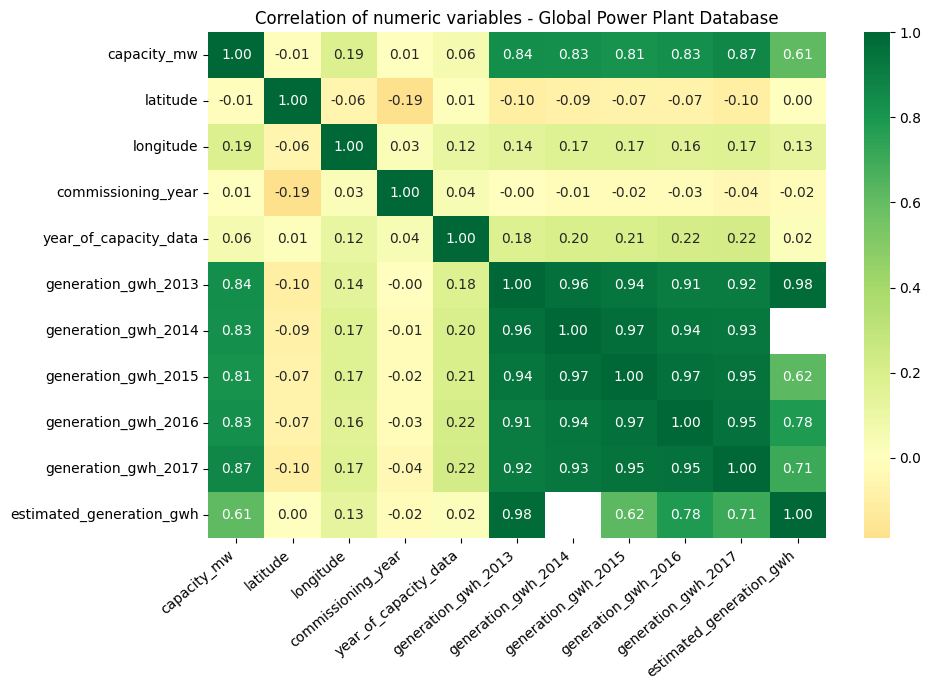

In [33]:
corr = df_power.drop(columns='commissioning_year_raw').select_dtypes("number").corr()

plt.figure(figsize=(10, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdYlGn", center=0)
plt.title("Correlation of numeric variables - Global Power Plant Database")
plt.xticks(rotation=40, ha='right')  # Tilt bottom labels to 40 degrees
plt.tight_layout()
plt.savefig(OUTPUT_PATH + 'correlation_heatmap.png', dpi=200)
plt.show()

### **Interpretations**

**Strongest relationships:**

(1) The five yearly generation columns correlate 0.91 to 0.97 with each other, so they carry the same information and only 2017 is needed as the target.

(2) Capacity correlates strongly with generation in every year (0.81 to 0.87), strongest with 2017 at 0.87.

(3) Estimated generation is WRI’s own estimate for 2014, filled in only where real 2014 data is missing (no plant has both). Its 0.98 with 2013 looks very strong, but it rests on only 103 plants. With 2017 it is 0.71 on 1,832 plants. Different plants sit behind each number, so they can’t be compared. It is a model output, not measured generation, so I leave it out of the modelling.

**Near-zero relationships:**

Commissioning year is close to zero with capacity (0.01) and all generation years (-0.04 to 0.00), so plant age does not predict size or output. Its only noticeable link is a weak -0.19 with latitude, which I will not read into. Latitude and longitude are near zero with everything and are kept for the map only.

**Caution:** Coefficients use raw skewed values and are mostly driven by US plants. They are a first signal, to be checked with log-scale scatterplots in Task 4.

# Scatterplot and Pair Plot
**Exercise#4: Scatterplot and pair plot.** Create a scatterplot for the variable pair with your strongest correlation, and a full pair plot of your dataset. Discuss whether the relationship looks linear, note any outliers, and mark which variables you want to explore further. Submit both charts plus your written interpretation.


**Note:** As we know **Capacity_MW is heavily skewed**, so I apply a log transform before K-means. Otherwise a few giant plants dominate the distance calculation and the clusters wouldn’t be meaningful.

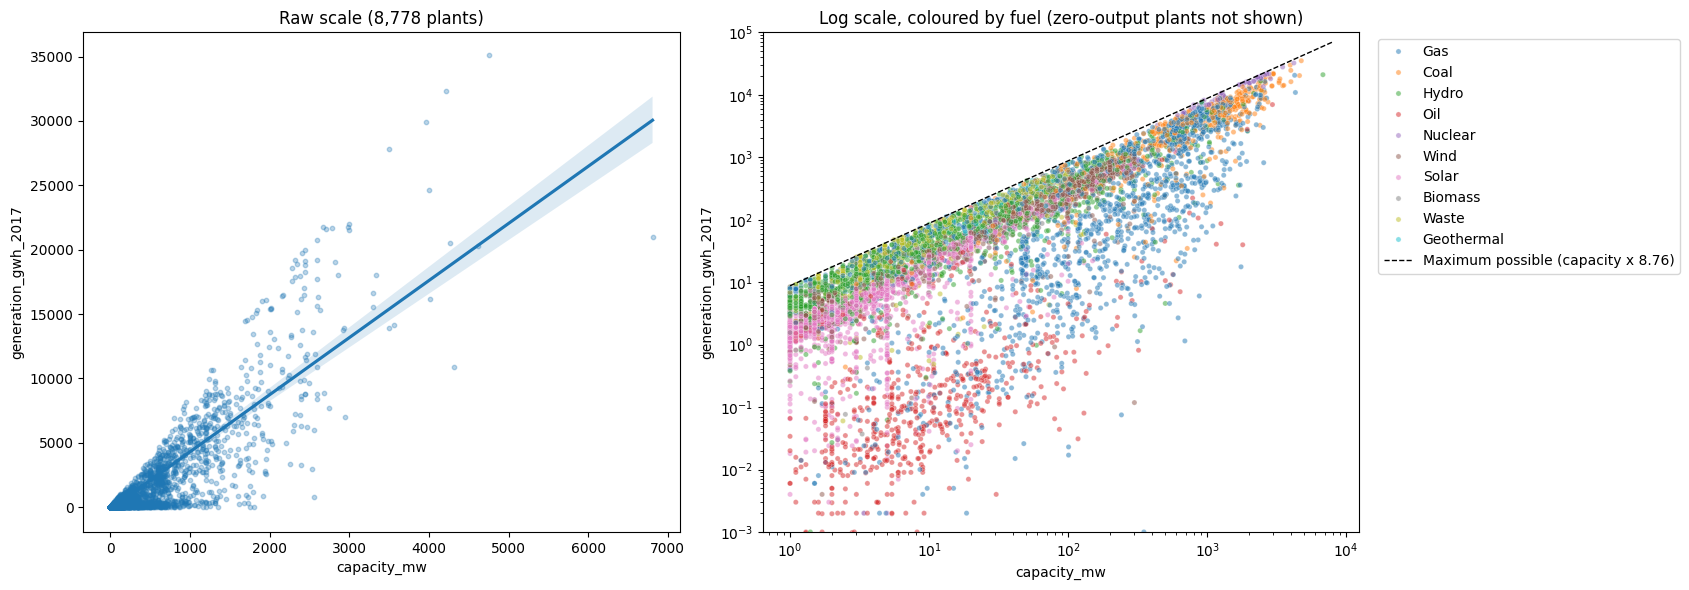

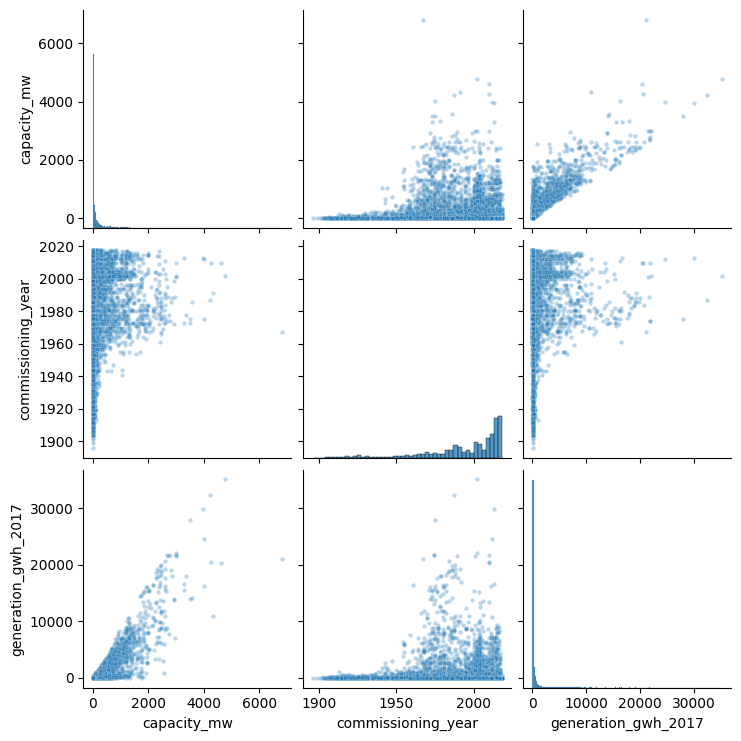

In [34]:
counts = df_final['primary_fuel'].value_counts()
main_fuels = counts[counts >= 50].index
plot_df = df_final[df_final['primary_fuel'].isin(main_fuels)]

fig, ax = plt.subplots(1, 2, figsize=(17, 6))

sns.regplot(data=df_final, x="capacity_mw", y="generation_gwh_2017", ax=ax[0], scatter_kws={"alpha": 0.3, "s": 10})
ax[0].set_title("Raw scale (8,778 plants)")

sns.scatterplot(data=plot_df, x="capacity_mw", y="generation_gwh_2017", hue="primary_fuel", alpha=0.5, s=14, ax=ax[1])
x = np.logspace(0, 3.9, 50)
ax[1].plot(x, x * 8.76, "k--", linewidth=1, label="Maximum possible (capacity x 8.76)")
ax[1].set_xscale("log")
ax[1].set_yscale("log")
ax[1].set_ylim(1e-3, 1e5)
ax[1].set_title("Log scale, coloured by fuel (zero-output plants not shown)")
ax[1].legend(bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.savefig(OUTPUT_PATH + 'scatter_capacity_vs_generation.png', dpi=200, bbox_inches='tight')
plt.show()

g = sns.pairplot(df_final[["capacity_mw", "commissioning_year", "generation_gwh_2017"]], plot_kws={"alpha": 0.3, "s": 10})
g.savefig(OUTPUT_PATH + 'pairplot_modelling_vars.png', dpi=200)

## Interpretations

**Why two charts?** Most power plants are small and a few are giants. On a normal (raw) scale the giants stretch the axes, so the small plants get squashed into one corner. The left chart (raw scale, 8,778 plants) shows the overall trend line and the extreme plants. The right chart uses a log scale, where each step is ten times bigger (1, 10, 100, 1,000), so small and large plants can both be read. It is coloured by fuel to test what explains the spread. Zero-output plants cannot be shown on a log scale, and the right chart also leaves out 87 plants whose fuel has fewer than 50 plants in the modelling set (so it shows 8,691 plants).

**Scatterplot (capacity vs 2017 generation):** Generation rises with capacity, matching the 0.87 correlation. The relationship is roughly linear but fans out: small plants sit tightly together, while large plants vary widely. Most plants are packed into the bottom-left corner (under about 1,000 MW), which is why the log view is needed. Outliers above the trend line (4,000 to 4,750 MW producing 25,000 to 35,000 GWh) run at roughly 70% to 85% of their maximum. The outlier far below it (about 6,800 MW producing only about 21,000 GWh) runs at about 35% of its maximum.

Coloured by fuel, the plants form layers, not an even mix. Nuclear sits closest to the maximum-output line, coal and hydro in the middle, wind and solar lower, and oil and gas lowest, with gas spread very widely. Later colours are drawn over earlier ones, so some overlap is hidden. Fuel therefore explains part of the spread around the capacity trend, but not all, since gas alone covers nearly the whole range. The categorical plot below measures this with capacity factor.

**Pair plot:** I plotted the 3 modelling variables, not every numeric column. The yearly generation columns repeat the same information, `estimated_generation_gwh` is a modelled estimate, and latitude and longitude are only for the map.

Capacity and 2017 generation show a clear rising band, the one real relationship. Commissioning year shows no pattern against capacity or generation: very large plants mostly appear after about 1960, but newer plants are not bigger or higher-producing. Capacity and generation are heavily skewed, with most plants piled near zero, which is why I use a log transform before clustering. The commissioning year histogram shows many more plants built recently.

**To explore further:** `capacity_mw`, `primary_fuel` (the likely cause of the spread) and generation on a log scale. Commissioning year is a weak candidate.

# Categorical Plot and Research Question Check-in
**Exercise#5: Categorical plot and research question check-in**. Create one categorical plot exploring a variable split you are curious about. Then revisit your Lesson 1 umbrella question and sub-questions: answer what you can now, add any new questions this exploration raised, and write down the hypotheses you are carrying into Lesson 4. Record this in a running Capstone_Findings.docx. Start it here, and add to it after each of Lessons 3 through 6, so Lesson 7's dashboard and case study have real findings to draw on. Submit the categorical plot, your updated questions and hypotheses, and the findings document.

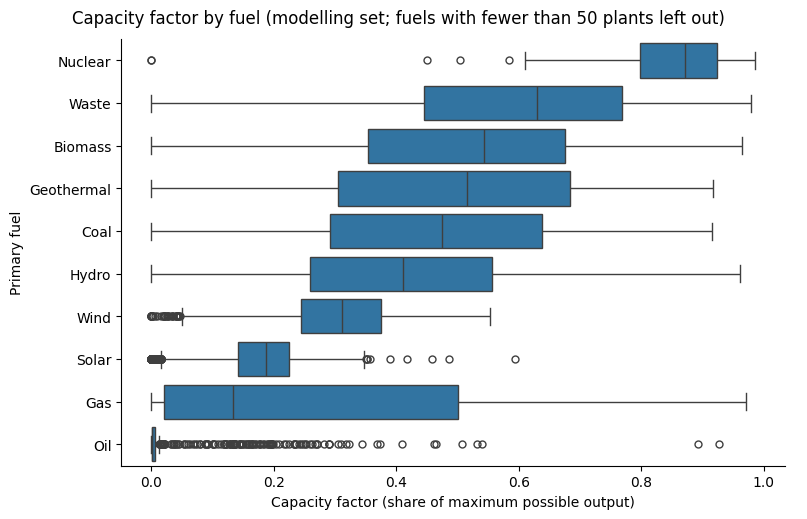

In [35]:
df_final['capacity_factor'] = df_final['generation_gwh_2017'] / (df_final['capacity_mw'] * 8.76)

counts = df_final['primary_fuel'].value_counts()
main_fuels = counts[counts >= 50].index
plot_df = df_final[df_final['primary_fuel'].isin(main_fuels)]
order = plot_df.groupby('primary_fuel')['capacity_factor'].median().sort_values(ascending=False).index

g = sns.catplot(data=plot_df, x='capacity_factor', y='primary_fuel', kind='box', order=order, height=5, aspect=1.6)
g.set_axis_labels("Capacity factor (share of maximum possible output)", "Primary fuel")
g.figure.suptitle("Capacity factor by fuel (modelling set; fuels with fewer than 50 plants left out)", y=1.03)
g.savefig(OUTPUT_PATH + 'capacity_factor_by_fuel.png', dpi=200, bbox_inches='tight')

### Categorical plot: capacity factor by fuel type

**Why this chart:** The scatterplot showed that plants of the same size produce very different amounts of electricity. Size alone does not explain this, so I tested fuel type as the reason.

**What is capacity factor?** The share of its maximum possible yearly output that a plant actually produced: 2017 generation ÷ (capacity × 8.76). A value of 1.0 means the plant ran flat out all year, and 0.2 means it produced 20% of its maximum. Using this measure removes the effect of plant size, so any difference left comes from the fuel.

**How to read the chart:** Each row is one fuel. The box covers the middle half of plants, the line inside it is the typical plant, and the dots are unusual plants. Fuels with fewer than 50 plants are left out because their results would be unreliable. Based on the 8,778 modelling plants (95% US).

**What I see:**
- Nuclear runs the hardest: typical plant about 87% of maximum.
- Waste, biomass, geothermal, coal and hydro are in the middle: about 40% to 63%.
- Wind (about 31%) and solar (about 19%) run lower, as expected for weather-dependent fuels.
- Gas has a typical value of only about 13%, but a very wide box (about 2% to 50%), so gas plants behave very differently from each other.
- Oil is close to zero: oil plants barely run.

**So what:** Fuel type explains much of the spread that capacity alone could not. This supports including `primary_fuel` in the regression.

**Carry forward:**
- Small fuel categories (e.g. storage, cogeneration, petcoke) need grouping or exclusion before modelling.
- Questions to check later: why oil plants barely run (probably backup use), and why gas varies so widely (baseload and peaking plants may be mixed).
- These patterns come from mostly US plants. They cannot be assumed to hold for Saudi Arabia, where oil and gas are the main fuels. This is a hypothesis, not a result.

## Research Question Check-in

**Research question check-in**
Umbrella question (revised): How does installed power plant capacity vary across countries and fuel types worldwide, and, in the subset of plants that report actual 2017 generation (mostly US), which plant characteristics, measured by R-squared and feature weights in a regression model, best explain differences in output?


**Revision note:** the original question asked how capacity and generation vary across countries. Generation data exists for only six countries and none for Saudi Arabia, so the capacity comparison stays global, and the generation analysis is limited to where data exists. The original wording is kept in the research brief for the record. No change was needed in Lesson 2.

**Sub-question Status after Lesson 2	Next**
1. Top 15 countries by capacity (global, includes Saudi Arabia)	Not answered yet. Saudi Arabia has 86 plants and 84,218 MW.	Lesson 3 (choropleth)
2. Clustering (US-based, N = 8,778)	Not answered yet. Inputs: log capacity, log generation, commissioning year.	Lesson 4
3. Regression (US-based, N = 8,778)	Partly answered: capacity is the strongest single predictor, fuel type matters beyond size, commissioning year looks weak. R-squared still to be measured.	Lesson 5
4. Time series by fuel (expected US-heavy)	Not answered yet. Country coverage of the 2013 to 2016 columns must be checked first.	Lesson 6


**New questions raised**

1.	Why do oil plants barely run (typical capacity factor near zero)? Probably backup use, to be checked.
2.	Why do gas plants vary so widely (about 2% to 50%)? Baseload and peaking plants may be mixed together.
3.	Do these US fuel patterns apply to Saudi Arabia, where oil and gas supply nearly all of the 86 plants in the database?


**Hypotheses carried into Lesson 4**

1.	Plants will cluster mainly by size, and then by how hard they run.


2.	Clusters will separate fuel types: nuclear, coal and hydro in high-output groups, solar and wind lower, oil and many gas plants lowest.


3.	Commissioning year will not define any cluster on its own.


# Check: Numbers Quoted in the Write-up

In [36]:
print("Countries:", df_power['country'].nunique())
print('\n',df_power['primary_fuel'].value_counts())

has_estimated_gen = df_power['estimated_generation_gwh'].notna()
for y in [2013, 2014, 2017]:
    print(f"Estimate and {y} generation both present:", int((has_estimated_gen & df_power[f'generation_gwh_{y}'].notna()).sum()))

Countries: 164

 primary_fuel
Hydro             7155
Solar             5929
Wind              5188
Gas               3922
Coal              2390
Oil               2290
Biomass           1396
Waste             1087
Nuclear            198
Geothermal         189
Storage             58
Other               44
Cogeneration        41
Petcoke             13
Wave and Tidal      10
Name: count, dtype: int64
Estimate and 2013 generation both present: 103
Estimate and 2014 generation both present: 0
Estimate and 2017 generation both present: 1832


**What this cell does:** Several numbers in the markdown above (countries, fuel counts) were calculated while exploring the data. This cell recalculates them from `df_power` so each can be checked against the text:

* number of countries and plants per fuel type (Data Profile)
* how many plants have both an estimated generation figure and real generation for 2013, 2014 and 2017 (heatmap note)

**Result:** *Every number in the groups above matched the text.*

In [37]:
df_final.to_pickle(OUTPUT_PATH + 'model_ready_plants.pkl')
print("Saved: model_ready_plants.pkl: ", df_final.shape[0], "rows,", df_final.shape[1], "columns")

Saved: model_ready_plants.pkl:  8778 rows, 28 columns


## **End**